In [1]:
# Libraries
import os
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.ticker import PercentFormatter


In [2]:
# ===== 1. DATA COLLECTION AND CLEANING =====
# Load ESG risk ratings (Kaggle, Sustainalytics 2023)
esg = pd.read_csv("../data/SP 500 ESG Risk Ratings.csv")
esg.info()

<class 'pandas.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Symbol                  503 non-null    str    
 1   Name                    503 non-null    str    
 2   Address                 502 non-null    str    
 3   Sector                  502 non-null    str    
 4   Industry                502 non-null    str    
 5   Full Time Employees     498 non-null    str    
 6   Description             502 non-null    str    
 7   Total ESG Risk score    430 non-null    float64
 8   Environment Risk Score  430 non-null    float64
 9   Governance Risk Score   430 non-null    float64
 10  Social Risk Score       430 non-null    float64
 11  Controversy Level       430 non-null    str    
 12  Controversy Score       403 non-null    float64
 13  ESG Risk Percentile     430 non-null    str    
 14  ESG Risk Level          430 non-null    str    
dtype

In [3]:
# Keep relevant columns
columns_to_keep = [
    "Symbol", "Name", "Sector", "Industry", "Full Time Employees",
    "Total ESG Risk score", "Environment Risk Score",
    "Social Risk Score", "Governance Risk Score",
    "Controversy Level", "Controversy Score",
    "ESG Risk Percentile", "ESG Risk Level"
]
esg = esg[columns_to_keep].copy()

In [4]:
# Rename columns to snake_case
esg.columns = [
    "ticker", "company_name", "sector", "industry", "employees",
    "esg_total", "esg_environmental", "esg_social", "esg_governance",
    "controversy_level", "controversy_score",
    "esg_percentile", "esg_level"
]
esg.head()

,ticker,company_name,sector,industry,employees,esg_total,esg_environmental,esg_social,esg_governance,controversy_level,controversy_score,esg_percentile,esg_level
0,ENPH,"Enphase Energy, Inc.",Technology,Solar,"3,157",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,EMN,Eastman Chemical Company,Basic Materials,Specialty Chemicals,"14,000",25.3,12.8,5.8,6.6,Moderate Controversy Level,2.0,50th percentile,Medium
2,DPZ,Domino's Pizza Inc.,Consumer Cyclical,Restaurants,"6,500",29.2,10.6,12.2,6.3,Moderate Controversy Level,2.0,66th percentile,Medium
3,DAY,"Dayforce, Inc.",Technology,Software - Application,"9,084",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DVA,Davita Inc.,Healthcare,Medical Care Facilities,"70,000",22.6,0.1,14.1,8.4,Moderate Controversy Level,2.0,38th percentile,Medium


In [5]:
# Remove thousands separators and convert to numeric
esg["employees"] = esg["employees"].str.replace(",", "").astype(float)

# Extract the number from text like "50th percentile"
esg["esg_percentile"] = esg["esg_percentile"].str.extract(r"(\d+)").astype(float)

esg.info()

<class 'pandas.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ticker             503 non-null    str    
 1   company_name       503 non-null    str    
 2   sector             502 non-null    str    
 3   industry           502 non-null    str    
 4   employees          498 non-null    float64
 5   esg_total          430 non-null    float64
 6   esg_environmental  430 non-null    float64
 7   esg_social         430 non-null    float64
 8   esg_governance     430 non-null    float64
 9   controversy_level  430 non-null    str    
 10  controversy_score  403 non-null    float64
 11  esg_percentile     430 non-null    float64
 12  esg_level          430 non-null    str    
dtypes: float64(7), str(6)
memory usage: 51.2 KB


In [6]:
# Companies without ESG score
missing_esg = esg[esg["esg_total"].isna()]
print(f"Companies without ESG score: {len(missing_esg)}")

# Which sectors are they in?
missing_esg["sector"].value_counts()

Companies without ESG score: 73


sector
Technology                15
Industrials               13
Healthcare                12
Communication Services     8
Consumer Cyclical          6
Utilities                  4
Real Estate                3
Financial Services         3
Basic Materials            3
Consumer Defensive         3
Energy                     2
Name: count, dtype: int64

In [7]:
# Keep only companies with an ESG score
esg_clean = esg.dropna(subset=["esg_total"]).copy()
print(f"Companies before: {len(esg)} | after: {len(esg_clean)}")

Companies before: 503 | after: 430


In [8]:
# Test download with a single ticker
test = yf.download("AAPL", start="2019-01-01", end="2025-12-31")
test.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2019-01-02,37.436913,37.657383,36.562151,36.718613,148158800
2019-01-03,33.707924,34.544754,33.662881,34.132264,365248800
2019-01-04,35.146896,35.215647,34.089599,34.262654,234428400
2019-01-07,35.068668,35.282027,34.587432,35.251208,219111200
2019-01-08,35.737175,35.990834,35.208527,35.455070,164101200


In [9]:
# Yahoo Finance uses "-" instead of "." in tickers (e.g. BRK.B -> BRK-B)
tickers = esg_clean["ticker"].str.replace(".", "-", regex=False).tolist()

# Download closing prices for all tickers
prices = yf.download(tickers, start="2019-01-01", end="2025-12-31")["Close"]
print(prices.shape)

[*****                 10%                       ]  44 of 430 completed$EA: Data doesn't exist for startDate = 1546318800, endDate = 1767157200
[********              16%                       ]  70 of 430 completed$MRO: possibly delisted; no timezone found
[***********           22%                       ]  93 of 430 completed$BK: Data doesn't exist for startDate = 1546318800, endDate = 1767157200
[***********           23%                       ]  97 of 430 completed$HOLX: possibly delisted; no timezone found
[*************         28%                       ]  121 of 430 completed$IPG: possibly delisted; no price data found  (1d 2019-01-01 -> 2025-12-31)
[******************    37%                       ]  159 of 430 completed$CTRA: Data doesn't exist for startDate = 1546318800, endDate = 1767157200
[**********************54%*                      ]  231 of 430 completed$CMA: Data doesn't exist for startDate = 1546318800, endDate = 1767157200
[**********************57%**              

(1759, 430)


In [10]:
# Tickers with no data at all
failed = prices.columns[prices.isna().all()].tolist()
print(f"Failed tickers: {len(failed)}")

# Retry download for failed tickers only
retry = yf.download(failed, start="2019-01-01", end="2025-12-31")["Close"]
prices.update(retry)

# Check which ones still have no data
still_failed = prices.columns[prices.isna().all()].tolist()
print(f"Still failing after retry: {len(still_failed)}")
print(still_failed)

$ANSS: possibly delisted; no timezone found
$QRVO: Data doesn't exist for startDate = 1546318800, endDate = 1767157200
[                       0%                       ]

Failed tickers: 18


$K: possibly delisted; no price data found  (1d 2019-01-01 -> 2025-12-31)
[*****                 11%                       ]  2 of 18 completed$IPG: possibly delisted; no price data found  (1d 2019-01-01 -> 2025-12-31)
[********              17%                       ]  3 of 18 completed$HES: possibly delisted; no timezone found
[***********           22%                       ]  4 of 18 completed$WBA: possibly delisted; no timezone found
[*************         28%                       ]  5 of 18 completed$MRO: possibly delisted; no timezone found
[****************      33%                       ]  6 of 18 completed$AVB: Data doesn't exist for startDate = 1546318800, endDate = 1767157200
[*******************   39%                       ]  7 of 18 completed$DFS: possibly delisted; no timezone found
[*******************   39%                       ]  7 of 18 completed$MMC: possibly delisted; no timezone found
[**********************50%                       ]  9 of 18 completed$FI: Data

Still failing after retry: 18
['ANSS', 'AVB', 'BK', 'CMA', 'CTRA', 'DFS', 'EA', 'EQR', 'FI', 'HES', 'HOLX', 'IPG', 'JNPR', 'K', 'MMC', 'MRO', 'QRVO', 'WBA']


In [11]:
# Drop tickers without price data from both tables
prices = prices.drop(columns=still_failed)
esg_clean = esg_clean[~esg_clean["ticker"].isin(still_failed)].copy()

print(f"Companies with ESG and prices: {len(esg_clean)}")
print(f"Price table shape: {prices.shape}")

Companies with ESG and prices: 412
Price table shape: (1759, 412)


In [12]:
# Check that a failing ticker also fails on its own
yf.download("BK", start="2019-01-01", end="2025-12-31")["Close"].head()

$BK: Data doesn't exist for startDate = 1546318800, endDate = 1767157200
[*********************100%***********************]  1 of 1 completed

1 Failed download:
['BK']: Data doesn't exist for startDate = 1546318800, endDate = 1767157200


Ticker,BK


In [13]:
# Share of missing days per company (top 10)
missing_share = prices.isna().mean().sort_values(ascending=False)
missing_share.head(10)

Ticker
PARA    0.303013
ABBV    0.000000
ABT     0.000000
ACGL    0.000000
ACN     0.000000
ADBE    0.000000
ADI     0.000000
ADM     0.000000
ADP     0.000000
ADSK    0.000000
dtype: float64

In [14]:
# Date range with available prices for PARA
print(prices["PARA"].first_valid_index())
print(prices["PARA"].last_valid_index())

2021-02-12 00:00:00
2025-12-30 00:00:00


In [15]:
# Drop PARA: 30% of the period has no price data
prices = prices.drop(columns=["PARA"])
esg_clean = esg_clean[esg_clean["ticker"] != "PARA"].copy()

print(f"Final sample: {len(esg_clean)} companies")

prices.to_csv("../data/prices_raw.csv")
esg_clean.to_csv("../data/esg_clean.csv", index=False)

Final sample: 411 companies


In [16]:
# ===== 2. PERFORMANCE AND RISK METRICS =====
esg = esg_clean.reset_index(drop=True)

print(prices.shape, esg.shape)

(1759, 411) (411, 13)


In [17]:
# Daily percentage change in price
daily_returns = prices.pct_change()
daily_returns.head()

Ticker,A,AAL,AAPL,ABBV,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WRB,WTW,WY,WYNN,XEL,XOM,XYL,YUM,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2019-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-03,-0.036840,-0.074507,-0.099608,-0.032948,-0.047194,-0.015655,-0.034142,-0.039498,-0.060405,-0.004396,...,-0.016570,-0.020978,0.033907,-0.009674,-0.003940,-0.015354,-0.034280,-0.025153,-0.018088,-0.034564
2019-01-04,0.034614,0.065868,0.042689,0.032217,0.028541,0.023662,0.038884,0.048632,0.024279,0.023056,...,0.015445,0.027023,0.034142,0.040333,0.009785,0.036870,0.042192,0.026027,0.034153,0.039235
2019-01-07,0.021234,0.028402,-0.002226,0.014595,0.014976,-0.002274,0.003474,0.013573,0.006288,0.005035,...,0.002904,0.007375,0.019983,0.017758,-0.004330,0.005200,-0.014789,-0.001094,0.000385,0.006017
2019-01-08,0.014660,-0.016085,0.019063,0.004647,-0.012006,0.003798,0.025290,0.014918,0.024396,0.018607,...,-0.007308,0.006398,0.005963,0.031333,0.011597,0.007271,0.009401,-0.001970,-0.022425,0.014894


In [18]:
# Annualised return (CAGR) over the whole period
years = (prices.index[-1] - prices.index[0]).days / 365.25
annual_return = (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1

# Annualised volatility (252 trading days per year)
volatility = daily_returns.std() * np.sqrt(252)

# Maximum drawdown: worst fall from a previous peak
drawdown = prices / prices.cummax() - 1
max_drawdown = drawdown.min()

# Return during the COVID crash (market peak to bottom)
covid_crash = prices.loc["2020-03-23"] / prices.loc["2020-02-19"] - 1

# Return in 2022 (rate-hike year)
year_end = prices.resample("YE").last()
return_2022 = year_end.loc["2022"].iloc[0] / year_end.loc["2021"].iloc[0] - 1

In [19]:
# Combine metrics into one table and check ranges
metrics = pd.DataFrame({
    "annual_return": annual_return,
    "volatility": volatility,
    "max_drawdown": max_drawdown,
    "covid_crash": covid_crash,
    "return_2022": return_2022
})
metrics.index.name = "ticker"
metrics = metrics.reset_index()

metrics.describe().round(3)

,annual_return,volatility,max_drawdown,covid_crash,return_2022
count,411.000,411.000,411.000,411.000,411.000
mean,0.128,0.333,-0.512,-0.380,-0.077
std,0.108,0.085,0.140,0.143,0.267
min,-0.176,0.192,-0.901,-0.849,-0.650
25%,0.064,0.274,-0.591,-0.459,-0.250
50%,0.120,0.317,-0.488,-0.380,-0.108
75%,0.186,0.370,-0.416,-0.301,0.065
max,0.776,0.701,-0.238,0.137,1.191


In [20]:
# Join ESG data and metrics
df = esg.merge(metrics, on="ticker", how="inner")
print(f"Companies in final dataset: {len(df)}")

df.to_csv("../data/analysis_dataset.csv", index=False)

Companies in final dataset: 411


In [21]:
# Inspect extreme values
cols = ["ticker", "company_name", "sector"]
print(df.nlargest(3, "covid_crash")[cols + ["covid_crash"]])
print(df.nlargest(3, "return_2022")[cols + ["return_2022"]])
print(df.nlargest(3, "annual_return")[cols + ["annual_return"]])

    ticker                   company_name             sector  covid_crash
102   REGN  Regeneron Pharmaceuticals Inc         Healthcare     0.136773
1      DPZ            Domino's Pizza Inc.  Consumer Cyclical     0.092667
241   GILD            Gilead Sciences Inc         Healthcare     0.088139
    ticker                      company_name  sector  return_2022
139    OXY  Occidental Petroleum Corporation  Energy     1.190984
264    XOM           Exxon Mobil Corporation  Energy     0.874091
184    MPC    Marathon Petroleum Corporation  Energy     0.866228
    ticker   company_name             sector  annual_return
143   NVDA    Nvidia Corp         Technology       0.776187
64    TSLA    Tesla, Inc.  Consumer Cyclical       0.555696
348   AVGO  Broadcom Inc.         Technology       0.495206


In [22]:
# ===== 3. ANALYSIS =====

# Order ESG risk levels from best to worst
order = ["Negligible", "Low", "Medium", "High", "Severe"]
df["esg_level"] = pd.Categorical(df["esg_level"], categories=order, ordered=True)

df["esg_level"].value_counts().sort_index()

esg_level
Negligible      5
Low           179
Medium        177
High           47
Severe          3
Name: count, dtype: int64

In [23]:
# Average ESG risk score by sector
df.groupby("sector")["esg_total"].agg(["mean", "count"]).sort_values("mean").round(1)

,mean,count
sector,,
Real Estate,13.3,26
Technology,16.7,57
Consumer Cyclical,19.2,51
Healthcare,20.6,51
Financial Services,21.1,59
Communication Services,21.2,11
Industrials,24.0,60
Consumer Defensive,25.4,32
Utilities,26.7,28


In [24]:
# Median metrics by ESG risk level (raw, not sector-adjusted)
metrics = ["annual_return", "volatility", "max_drawdown", "covid_crash", "return_2022"]
df.groupby("esg_level", observed=True)[metrics].median().round(3)

,annual_return,volatility,max_drawdown,covid_crash,return_2022
esg_level,,,,,
Negligible,0.114,0.334,-0.460,-0.372,-0.291
Low,0.131,0.322,-0.484,-0.362,-0.182
Medium,0.113,0.300,-0.477,-0.375,-0.066
High,0.106,0.363,-0.561,-0.429,0.128
Severe,0.134,0.385,-0.603,-0.515,0.874


In [25]:
# Companies in the Severe group
df[df["esg_level"] == "Severe"][["ticker", "company_name", "sector", "return_2022"]]

,ticker,company_name,sector,return_2022
139,OXY,Occidental Petroleum Corporation,Energy,1.190984
245,GE,General Electric Company,Industrials,-0.109232
264,XOM,Exxon Mobil Corporation,Energy,0.874091


In [26]:
# Merge small groups into three ESG risk groups
group_map = {
    "Negligible": "Low risk", "Low": "Low risk",
    "Medium": "Medium risk",
    "High": "High risk", "Severe": "High risk"
}
df["esg_group"] = df["esg_level"].map(group_map)
df["esg_group"] = pd.Categorical(
    df["esg_group"], categories=["Low risk", "Medium risk", "High risk"], ordered=True
)

df["esg_group"].value_counts().sort_index()

esg_group
Low risk       184
Medium risk    177
High risk       50
Name: count, dtype: int64

In [27]:
# Each metric relative to the median of its sector
for m in metrics:
    df[f"{m}_vs_sector"] = df[m] - df.groupby("sector")[m].transform("median")

adj_metrics = [f"{m}_vs_sector" for m in metrics]
df.groupby("esg_group", observed=True)[adj_metrics].median().round(3)

,annual_return_vs_sector,volatility_vs_sector,max_drawdown_vs_sector,covid_crash_vs_sector,return_2022_vs_sector
esg_group,,,,,
Low risk,0.000,-0.001,0.005,0.011,-0.011
Medium risk,0.001,-0.001,0.000,-0.005,-0.011
High risk,-0.006,0.033,-0.042,-0.031,0.080


In [28]:
# Statistical tests: Mann-Whitney (high vs low group) and Spearman (ESG score)
low = df[df["esg_group"] == "Low risk"]
high = df[df["esg_group"] == "High risk"]

results = []
for m in adj_metrics:
    # Do high- and low-risk companies differ?
    _, p_groups = stats.mannwhitneyu(high[m], low[m])
    # Is the ESG score correlated with the metric across all companies?
    rho, p_corr = stats.spearmanr(df["esg_total"], df[m])
    results.append({
        "metric": m,
        "median_diff_high_vs_low": high[m].median() - low[m].median(),
        "p_value_groups": p_groups,
        "spearman_rho": rho,
        "p_value_corr": p_corr
    })

pd.DataFrame(results).round(3)

,metric,median_diff_high_vs_low,p_value_groups,spearman_rho,p_value_corr
0,annual_return_vs_sector,-0.006,0.917,-0.037,0.460
1,volatility_vs_sector,0.034,0.001,0.141,0.004
2,max_drawdown_vs_sector,-0.048,0.006,-0.108,0.029
3,covid_crash_vs_sector,-0.042,0.003,-0.163,0.001
4,return_2022_vs_sector,0.091,0.006,0.057,0.253


In [29]:
# Robustness check: repeat the tests excluding the energy sector
df_ex = df[df["sector"] != "Energy"]
low_ex = df_ex[df_ex["esg_group"] == "Low risk"]
high_ex = df_ex[df_ex["esg_group"] == "High risk"]

results_ex = []
for m in adj_metrics:
    _, p_groups = stats.mannwhitneyu(high_ex[m], low_ex[m])
    results_ex.append({
        "metric": m,
        "median_diff_high_vs_low": high_ex[m].median() - low_ex[m].median(),
        "p_value_groups": p_groups
    })

pd.DataFrame(results_ex).round(3)

,metric,median_diff_high_vs_low,p_value_groups
0,annual_return_vs_sector,-0.006,0.954
1,volatility_vs_sector,0.038,0.000
2,max_drawdown_vs_sector,-0.080,0.002
3,covid_crash_vs_sector,-0.045,0.002
4,return_2022_vs_sector,0.090,0.019


In [30]:
# Save final dataset
df.to_csv("../data/analysis_final.csv", index=False)

In [31]:
# ===== 4. CHARTS =====
# Folder to save charts for the README and presentation
os.makedirs("../figures", exist_ok=True)

sns.set_theme(style="whitegrid")
palette = {"Low risk": "#2a9d8f", "Medium risk": "#e9c46a", "High risk": "#e76f51"}

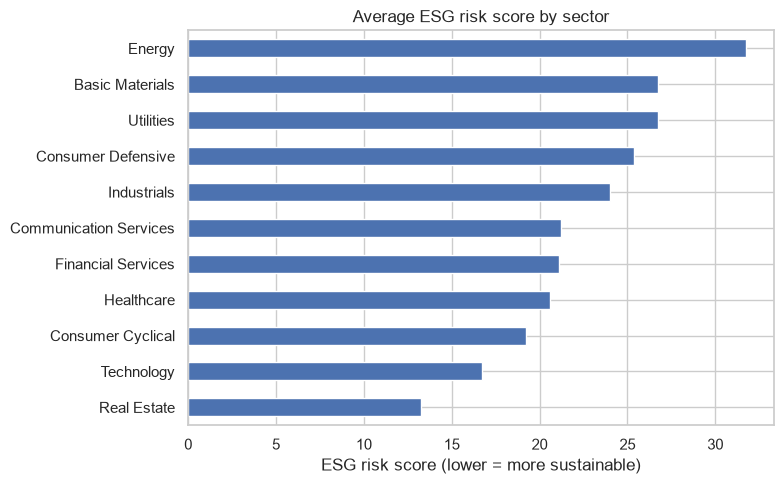

In [32]:
# Chart 1: ESG risk by sector
sector_esg = df.groupby("sector")["esg_total"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
sector_esg.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Average ESG risk score by sector")
ax.set_xlabel("ESG risk score (lower = more sustainable)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../figures/esg_by_sector.png", dpi=150)
plt.show()

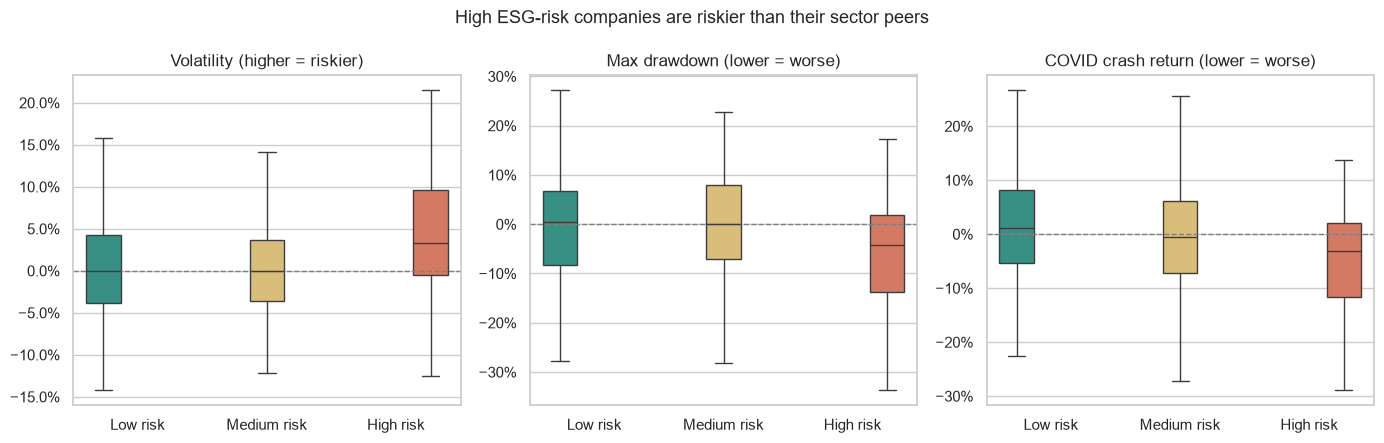

In [33]:
# Chart 2: risk metrics by ESG group, relative to sector
risk_cols = {
    "volatility_vs_sector": "Volatility (higher = riskier)",
    "max_drawdown_vs_sector": "Max drawdown (lower = worse)",
    "covid_crash_vs_sector": "COVID crash return (lower = worse)"
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (col, title) in zip(axes, risk_cols.items()):
    sns.boxplot(data=df, x="esg_group", y=col, hue="esg_group",
                palette=palette, legend=False, showfliers=False, ax=ax)
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.yaxis.set_major_formatter(PercentFormatter(1))

fig.suptitle("High ESG-risk companies are riskier than their sector peers", fontsize=13)
plt.tight_layout()
plt.savefig("../figures/risk_by_esg_group.png", dpi=150)
plt.show()

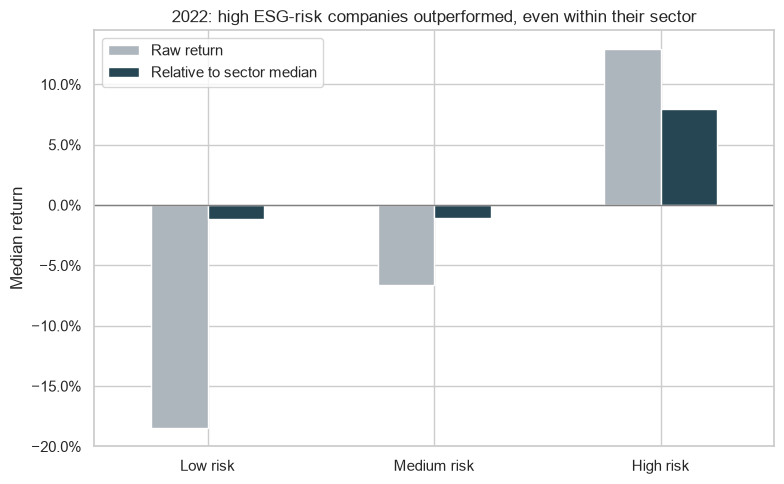

In [34]:
# Chart 3: 2022 returns, raw vs sector-adjusted
summary_2022 = df.groupby("esg_group", observed=True)[["return_2022", "return_2022_vs_sector"]].median()
summary_2022.columns = ["Raw return", "Relative to sector median"]

fig, ax = plt.subplots(figsize=(8, 5))
summary_2022.plot(kind="bar", ax=ax, color=["#adb5bd", "#264653"])
ax.axhline(0, color="grey", linewidth=1)
ax.set_title("2022: high ESG-risk companies outperformed, even within their sector")
ax.set_xlabel("")
ax.set_ylabel("Median return")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../figures/returns_2022.png", dpi=150)
plt.show()